# **Prueba Práctica 2 — Prototipo de Analítica de Ocupación

### Caso Nodo · Centro Comercial La Carolina (piso piloto)**

En este reto te pones en el lugar de **Rodrigo**: con presupuesto y cómputo para **una sola aplicación robusta**, debe decidir cuál de las tres candidatas —*analítica de ingreso*, *bienestar postural* o *control de acceso facial*— pilotar primero, y defender la elección ante el directorio con **evidencia**, no solo argumentos.

Este notebook es esa evidencia: un prototipo funcional de **analítica de ingreso** construido sobre **tracking multi-persona (YOLO + ByteTrack)**, con los tres productos del análisis temporal vistos en la semana:

1. **Tracking con identidad persistente** y cola de seguimiento que se desvanece (Paso 2)
2. **Mapa de calor** de tránsito acumulado (Paso 3)
3. **Contador de cruces** de una línea virtual, cada identidad una sola vez (Paso 4)

> **Vocabulario de la semana usado aquí:** *detección vs. tracking*, *tracking-by-detection*, *identidad persistente (ID)*, *asociación por IoU*, *análisis temporal*. ByteTrack mantiene el mismo ID de una persona entre cuadros usando predicción de movimiento (Kalman) + IoU, y rescata detecciones de baja confianza para sobrevivir a oclusiones.

**Entorno:** Python 3.14 · `ultralytics` (YOLOv26) · PyTorch (MPS en Apple Silicon) · OpenCV · NumPy 2.x. El notebook **no usa `cv2.imshow`**: escribe el video anotado a disco y muestra los resultados en línea con matplotlib, así corre en cualquier equipo (incluido sin pantalla).

---
## **Configuración**

Celda única de parámetros. Ajusta aquí rutas y umbrales; el resto del notebook los reutiliza.

In [1]:
import os, time, statistics
from collections import defaultdict, deque

import cv2
import numpy as np
import torch
from ultralytics import YOLO
import matplotlib.pyplot as plt

# --- Parámetros del prototipo ---
VIDEO_PATH   = "store.mp4"          # video de videovigilancia provisto
OUTPUT_DIR   = "resultados"         # carpeta de salidas (video anotado, imágenes)
MODEL_NAME   = "yolo26n.pt"         # YOLOv26 nano (rápido); se descarga solo
PERSON_CLASS = 0                    # clase "person" en COCO
CONF         = 0.30                 # umbral de confianza
TRAIL_LEN    = 30                   # largo de la cola de seguimiento (frames)
MAX_FRAMES   = None                 # None = procesar TODO el video; pon p.ej. 1500 para pruebas rápidas

# Dispositivo: GPU de Apple (MPS) si está disponible, si no CPU
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Propiedades del video (se usan en varios pasos)
_cap = cv2.VideoCapture(VIDEO_PATH)
assert _cap.isOpened(), f"No se pudo abrir el video: {VIDEO_PATH}"
W   = int(_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H   = int(_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
FPS = _cap.get(cv2.CAP_PROP_FPS) or 30.0
N   = int(_cap.get(cv2.CAP_PROP_FRAME_COUNT))
_cap.release()

print(f"Dispositivo de inferencia : {DEVICE}")
print(f"Resolución                : {W} x {H}")
print(f"FPS                       : {FPS:.1f}")
print(f"Total de cuadros          : {N}  (~{N/FPS:.0f} s)")

Matplotlib is building the font cache; this may take a moment.


Dispositivo de inferencia : mps
Resolución                : 1280 x 720
FPS                       : 30.0
Total de cuadros          : 10642  (~355 s)


---
## **Paso 1 — Explora el video**

Antes de escribir una sola línea de tracking, miramos los datos: es el mismo hábito profesional de la Semana 1 (*revisar los datos antes de construir el modelo*). Extraemos 4 cuadros espaciados en el tiempo y observamos flujo, zonas y **ángulo de cámara**, porque el ángulo condiciona la forma de las cajas delimitadoras que vamos a obtener.

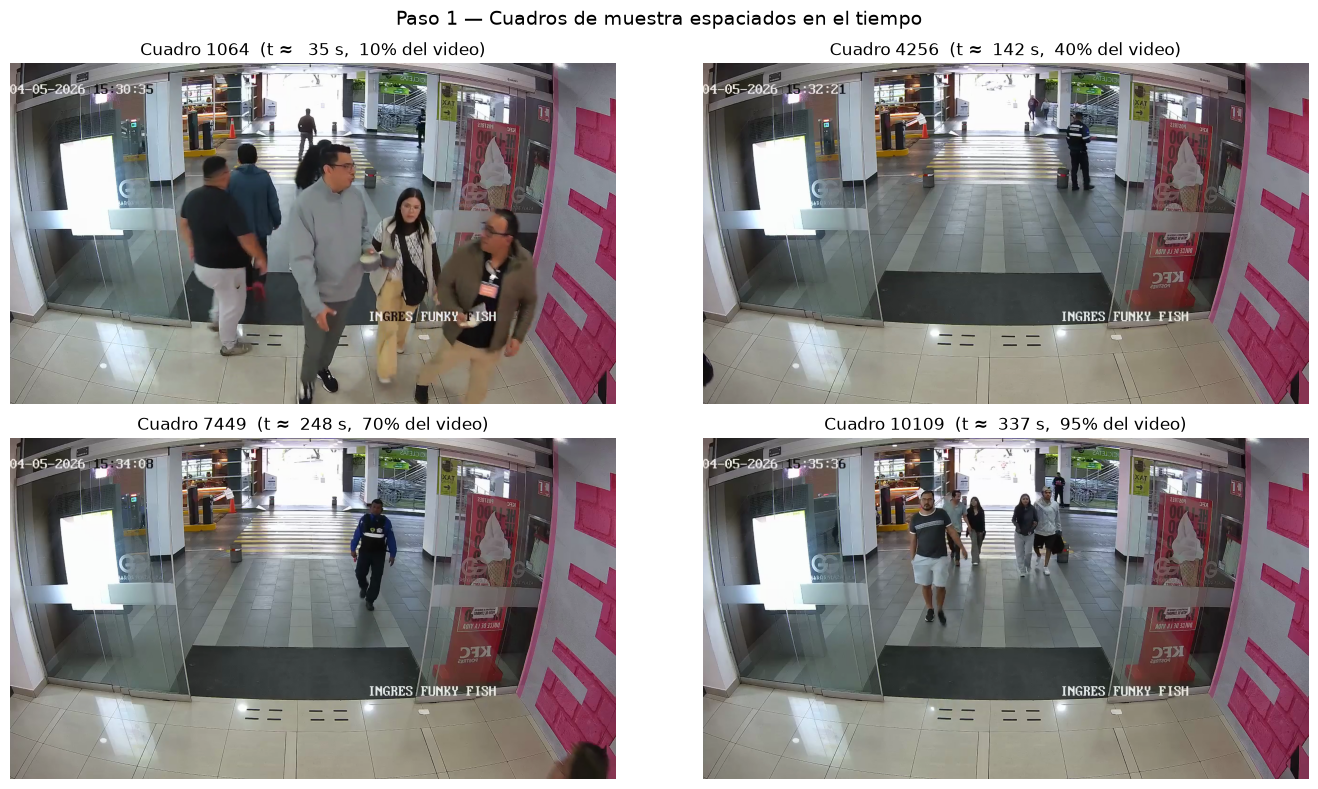

In [2]:
def leer_cuadro(path, idx):
    """Lee el cuadro número `idx` del video y lo devuelve en RGB."""
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, frame = cap.read()
    cap.release()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) if ok else None

# 4 cuadros espaciados a lo largo del video
fracciones = [0.10, 0.40, 0.70, 0.95]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, fr in zip(axes.ravel(), fracciones):
    idx = int(N * fr)
    img = leer_cuadro(VIDEO_PATH, idx)
    ax.imshow(img)
    ax.set_title(f"Cuadro {idx}  (t ≈ {idx/FPS:4.0f} s,  {fr*100:.0f}% del video)")
    ax.axis("off")
plt.suptitle("Paso 1 — Cuadros de muestra espaciados en el tiempo", fontsize=14)
plt.tight_layout(); plt.show()

### Observaciones (Paso 1)

- **Ubicación y ángulo de cámara.** Es una cámara CCTV **gran angular (tipo ojo de pez)** montada en alto y en ángulo **lateral/oblicuo**, no cenital. Mira a lo largo de un **pasillo de ingreso** del centro comercial. Consecuencia para el tracking: las cajas delimitadoras **no son uniformes** —las personas al fondo se ven pequeñas y las cercanas grandes— y hay **distorsión de barril** en los bordes, por lo que las cajas cerca de los extremos quedan deformadas. Esto afecta directamente el IoU usado por ByteTrack para asociar identidades.
- **Dónde se concentra el movimiento.** El tránsito ocurre casi todo en el **corredor central del fondo** (zona de la cebra/paso peatonal que conecta con el parqueadero y la calle). El **piso embaldosado en primer plano está casi siempre vacío**: la gente lo cruza poco. Esto anticipa dónde debe ir la línea de conteo (sobre el corredor) y dónde se encenderá el mapa de calor.
- **Momentos de mayor y menor tránsito.** El flujo es intermitente: hay cuadros con el pasillo vacío o solo el guardia de seguridad, y ráfagas con varias personas entrando/saliendo juntas. Los cruces en grupo o en paralelo son un riesgo conocido para el conteo (lo retomamos en el Paso 5).
- **Fuentes de ruido visibles.** Vidrios con **reflejos**, **vitrinas y carteles** (p. ej. el póster de KFC a la derecha) y el mostrador de guardianía pueden generar **detecciones espurias** de "persona". Lo tendremos presente al interpretar el mapa de calor.

---
## **Paso 2 — Detecta y trackea personas (YOLO + ByteTrack)**

Procesamos el video con `model.track(..., tracker="bytetrack.yaml")`, filtrando solo la clase **person**. Por cada persona dibujamos su **caja delimitadora**, su **ID de tracking** y una **cola de seguimiento que se desvanece** (los puntos viejos se achican y desaparecen). En una **única pasada del detector** guardamos también la trayectoria de cada identidad (`track_history`), que los Pasos 3 y 4 reutilizan —así no re-ejecutamos el detector: es la base de *análisis temporal construido sobre el tracking*.

In [3]:
model = YOLO(MODEL_NAME)

# Estructuras compartidas con los Pasos 3 y 4
trails        = defaultdict(lambda: deque(maxlen=TRAIL_LEN))  # cola visual (se desvanece)
track_history = defaultdict(list)                             # id -> [(frame, cx, cy), ...] trayectoria completa

out_path = os.path.join(OUTPUT_DIR, "paso2_tracking.mp4")
writer   = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))

rng = np.random.default_rng(42)
colores = {}  # color estable por ID
def color_de(tid):
    if tid not in colores:
        colores[tid] = tuple(int(c) for c in rng.integers(60, 255, size=3))
    return colores[tid]

ultimo_frame = None
t0 = time.time()
n_proc = 0

# stream=True -> generador cuadro a cuadro; persist del ID lo maneja ByteTrack
resultados = model.track(VIDEO_PATH, stream=True, classes=[PERSON_CLASS], conf=CONF,
                         tracker="bytetrack.yaml", device=DEVICE, verbose=False)

for i, r in enumerate(resultados):
    if MAX_FRAMES is not None and i >= MAX_FRAMES:
        break
    n_proc += 1
    frame = r.orig_img.copy()

    if r.boxes is not None and r.boxes.id is not None:
        xyxy = r.boxes.xyxy.cpu().numpy()
        ids  = r.boxes.id.int().cpu().tolist()
        for (x1, y1, x2, y2), tid in zip(xyxy, ids):
            x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
            col = color_de(tid)

            # Caja + etiqueta de identidad
            cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)
            cv2.putText(frame, f"ID {tid}", (x1, max(y1 - 8, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)

            # Registrar trayectoria (para Pasos 3 y 4) y cola visual
            track_history[tid].append((i, cx, cy))
            trails[tid].append((cx, cy))

            # Cola que se desvanece: puntos viejos pequeños, recientes grandes
            pts = list(trails[tid])
            for j in range(1, len(pts)):
                ratio = j / len(pts)                 # 0 (viejo) -> 1 (reciente)
                cv2.line(frame, pts[j - 1], pts[j], col, max(1, int(1 + 3 * ratio)))
            for j, (px, py) in enumerate(pts):
                ratio = (j + 1) / len(pts)
                cv2.circle(frame, (px, py), max(1, int(4 * ratio)), col, -1)

    cv2.putText(frame, f"Frame {i}  |  IDs activos acumulados: {len(track_history)}",
                (10, H - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
    writer.write(frame)
    ultimo_frame = frame

writer.release()
dt = time.time() - t0
print(f"Procesados {n_proc} cuadros en {dt:.1f} s  ({n_proc/dt:.1f} fps)")
print(f"Identidades (IDs) distintas vistas: {len(track_history)}")
print(f"Video anotado guardado en: {out_path}")

Procesados 10642 cuadros en 95.9 s  (111.0 fps)
Identidades (IDs) distintas vistas: 292
Video anotado guardado en: resultados/paso2_tracking.mp4


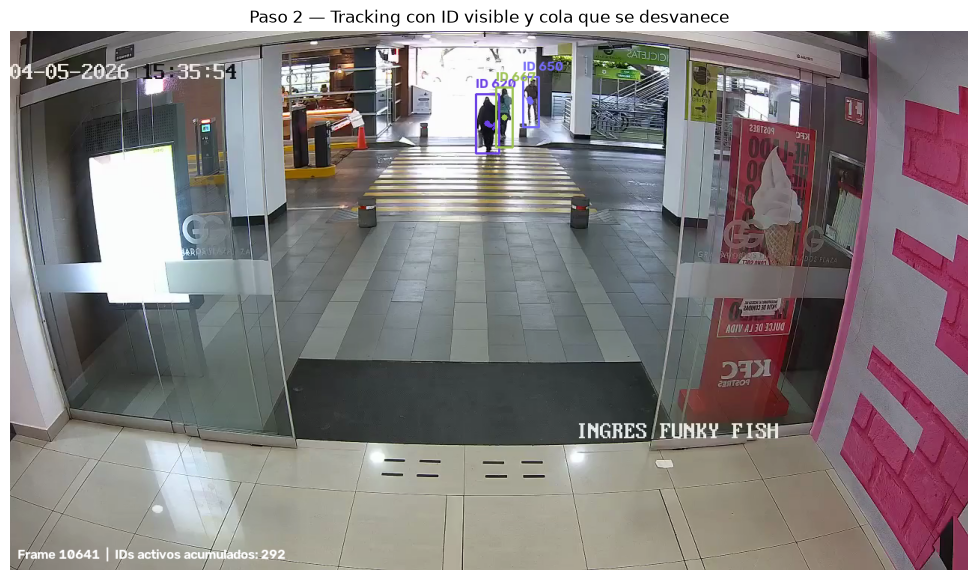

In [4]:
# Mostrar un cuadro anotado de ejemplo (el último procesado) con cajas, IDs y colas
plt.figure(figsize=(13, 7))
plt.imshow(cv2.cvtColor(ultimo_frame, cv2.COLOR_BGR2RGB))
plt.title("Paso 2 — Tracking con ID visible y cola que se desvanece")
plt.axis("off"); plt.show()

### Verificación de identidad persistente y oclusiones (Paso 2)

- **Persistencia del ID.** Mientras una persona permanece visible, ByteTrack le conserva el **mismo ID** entre cuadros consecutivos: eso es justamente la *identidad persistente* de la semana, y es la base de todo lo que sigue (sin ID estable no hay mapa de calor ni conteo correctos).
- **Qué mirar en las oclusiones.** Cuando una persona queda **momentáneamente oculta** detrás de otra o de un pilar, la pregunta clave es si al reaparecer **recupera su ID anterior** o si el sistema le asigna **uno nuevo**. ByteTrack rescata detecciones de baja confianza para mantener la identidad viva durante oclusiones cortas, pero en oclusiones largas o cruces muy cercanos **sí ocurren cambios de ID (ID switches)**. Esta observación alimenta directamente el Paso 5.

> Sugerencia: si el número de *IDs distintos* es mucho mayor que la cantidad real de personas que viste en el video, es señal de **fragmentación de identidades** por oclusiones —un límite honesto que Rodrigo debe reportar al directorio.

---
## **Paso 3 — Mapa de calor de tránsito**

Recorremos **todas las trayectorias** acumuladas en el Paso 2 y, por cada posición de centroide, sumamos sobre una grilla del tamaño de la escena. El resultado, suavizado y coloreado, se superpone sobre un cuadro del video: las zonas más calientes son las de **mayor tránsito**. Este es el producto que Rodrigo le muestra al directorio como evidencia de **qué zonas de La Carolina están subutilizadas y cuáles saturadas**.

Puntos de centroide acumulados: 23731


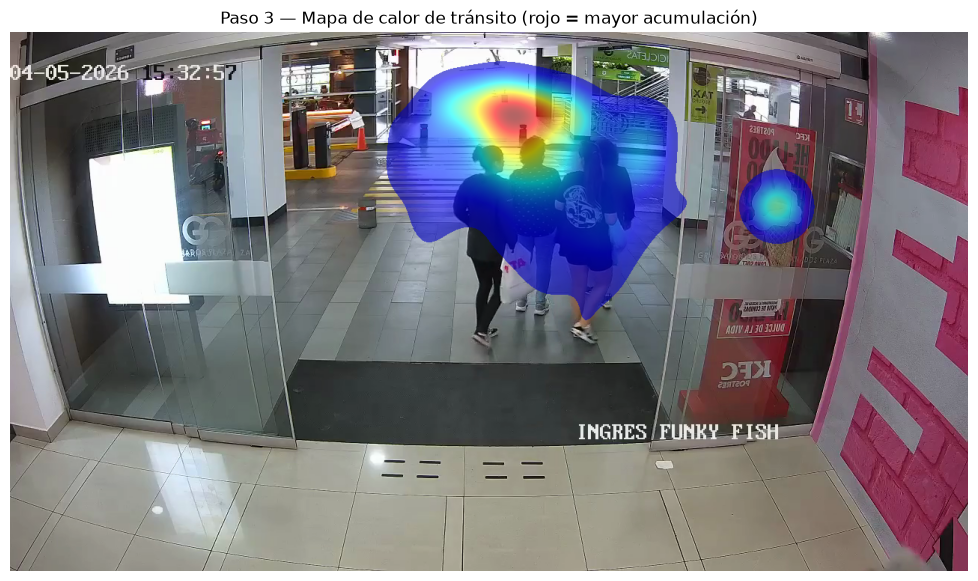

Mapa de calor guardado en: resultados/paso3_heatmap.png


In [5]:
# Acumular centroides de TODAS las identidades sobre una grilla (plano de la escena)
heat = np.zeros((H, W), dtype=np.float32)
n_pts = 0
for pts in track_history.values():
    for (_f, cx, cy) in pts:
        if 0 <= cy < H and 0 <= cx < W:
            heat[cy, cx] += 1.0
            n_pts += 1
print(f"Puntos de centroide acumulados: {n_pts}")

# Suavizar y normalizar a 0-255
heat_blur = cv2.GaussianBlur(heat, (0, 0), sigmaX=25, sigmaY=25)
heat_norm = (heat_blur / heat_blur.max() * 255).astype(np.uint8) if heat_blur.max() > 0 else heat_blur.astype(np.uint8)
heat_color = cv2.applyColorMap(heat_norm, cv2.COLORMAP_JET)

# Superponer sobre un cuadro representativo (mitad del video)
fondo = cv2.cvtColor(leer_cuadro(VIDEO_PATH, N // 2), cv2.COLOR_RGB2BGR)
# Mezclar solo donde hay actividad para no teñir toda la imagen
mask = (heat_norm > 15).astype(np.float32)[..., None]
overlay = (fondo * (1 - 0.6 * mask) + heat_color * (0.6 * mask)).astype(np.uint8)

heat_out = os.path.join(OUTPUT_DIR, "paso3_heatmap.png")
cv2.imwrite(heat_out, overlay)

plt.figure(figsize=(13, 7))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Paso 3 — Mapa de calor de tránsito (rojo = mayor acumulación)")
plt.axis("off"); plt.show()
print(f"Mapa de calor guardado en: {heat_out}")

### Lectura del mapa de calor (Paso 3)

El calor se concentra en el **corredor del fondo** (el paso que conecta con el parqueadero), confirmando la intuición del Paso 1: ahí está el flujo real, mientras el área embaldosada en primer plano permanece fría (subutilizada). Para Rodrigo esto es accionable: *dónde ampliar, dónde reubicar locales o señalética*.

> **Nota crítica:** cualquier punto caliente **fuera** del flujo peatonal (p. ej. sobre una vitrina o cartel) probablemente sea una **detección espuria** y no tránsito real. Interpretar el mapa exige descontar esas fuentes de ruido, no tomarlo literal.

---
## **Paso 4 — Contador de cruces de una línea virtual**

Definimos una **línea virtual** sobre una zona de paso claro (el corredor de ingreso) y, usando el **ID persistente**, contamos cuántas **identidades distintas** la cruzaron en cada dirección. Cada identidad se cuenta **una sola vez por dirección** (no una vez por cuadro): mantenemos un conjunto de IDs ya contados. Esto equivale a *"cuántas personas distintas ingresaron"* que Rodrigo necesita para la analítica de ingreso.

Personas distintas que INGRESARON (cruce hacia la cámara): 22
Personas distintas que SALIERON  (cruce hacia el fondo)  : 21
Flujo neto de ingreso: 1


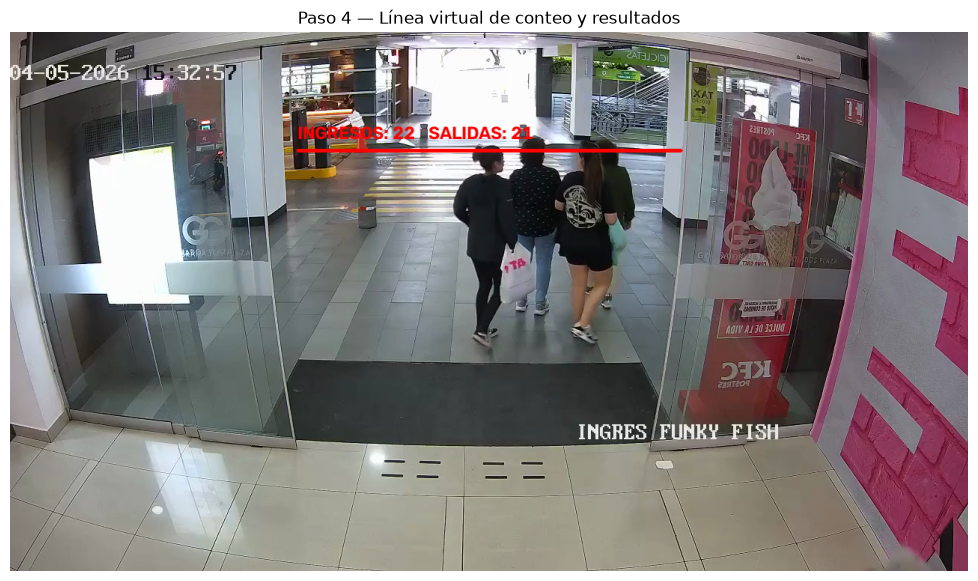

In [6]:
# Línea horizontal cruzando el corredor; se limita en X al ancho del corredor
# para no contar detecciones espurias de los bordes/vitrinas.
LINE_Y  = int(H * 0.22)     # altura de la línea
X_MIN   = int(W * 0.30)     # extremo izquierdo del tramo de conteo
X_MAX   = int(W * 0.70)     # extremo derecho

def cruza(py, cy):
    """Devuelve 'down', 'up' o None según cómo cruzó la línea entre py y cy."""
    if py < LINE_Y <= cy: return "down"   # hacia la cámara (ingreso al interior)
    if py > LINE_Y >= cy: return "up"      # hacia el fondo (salida)
    return None

cruces_down, cruces_up = set(), set()   # cada ID se agrega una sola vez por dirección
for tid, pts in track_history.items():
    for (_f1, px, py), (_f2, cx, cy) in zip(pts, pts[1:]):
        if X_MIN <= cx <= X_MAX:
            d = cruza(py, cy)
            if   d == "down": cruces_down.add(tid)
            elif d == "up":   cruces_up.add(tid)

print(f"Personas distintas que INGRESARON (cruce hacia la cámara): {len(cruces_down)}")
print(f"Personas distintas que SALIERON  (cruce hacia el fondo)  : {len(cruces_up)}")
print(f"Flujo neto de ingreso: {len(cruces_down) - len(cruces_up)}")

# Visualizar la línea y el tramo de conteo sobre un cuadro
viz = cv2.cvtColor(leer_cuadro(VIDEO_PATH, N // 2), cv2.COLOR_RGB2BGR)
cv2.line(viz, (X_MIN, LINE_Y), (X_MAX, LINE_Y), (0, 0, 255), 3)
cv2.putText(viz, f"INGRESOS: {len(cruces_down)}   SALIDAS: {len(cruces_up)}",
            (X_MIN, LINE_Y - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
cv2.imwrite(os.path.join(OUTPUT_DIR, "paso4_linea.png"), viz)
plt.figure(figsize=(13, 7))
plt.imshow(cv2.cvtColor(viz, cv2.COLOR_BGR2RGB))
plt.title("Paso 4 — Línea virtual de conteo y resultados")
plt.axis("off"); plt.show()

### Criterio de conteo (Paso 4)

- **Dirección = semántica de negocio.** Definimos *cruce hacia la cámara* = **ingreso** al interior del centro comercial, y *hacia el fondo* = **salida** hacia el parqueadero/calle. Es una convención explícita; en un despliegue real se calibra observando la geometría de cada cámara.
- **Sin doble conteo.** Como contamos **IDs en un conjunto**, una misma identidad cuenta una sola vez por dirección aunque aparezca cerca de la línea en muchos cuadros. La correctitud del conteo **depende por completo de la persistencia del ID** del Paso 2: si una persona cambia de ID por una oclusión, puede contarse dos veces.

---
## **Paso 5 — Límites del prototipo (honestidad técnica)**

Un prototipo que funciona razonablemente sobre un video de prueba **no es** un sistema validado para reportar cifras exactas al directorio sobre las cuatro cámaras del piso piloto. Límites observados:

1. **Conclusiones → identidades duplicadas (ID switches).** Cuando dos personas se cruzan o alguien pasa detrás de un pilar/otra persona, ByteTrack a veces pierde la identidad y asigna un **ID nuevo** al reaparecer. Esto **infla el número de IDs** y puede **duplicar un ingreso** en el contador. Es el riesgo más directo contra la exactitud del conteo.
2. **Cruces en paralelo / en grupo.** Si dos o más personas cruzan la línea **muy juntas o caminando en paralelo**, las cajas se solapan, el detector puede fusionarlas o perder una, y el conteo se **subestima**. La línea virtual asume cruces razonablemente separados.
3. **Distorsión de la cámara gran angular.** Las cajas cerca de los bordes están **deformadas** por el efecto ojo de pez, lo que degrada el IoU y, por tanto, la asociación de identidades en esas zonas.
4. **Detecciones espurias.** Reflejos en vidrios, carteles y maniquíes/pósters con figura humana pueden generar **falsos positivos** de "persona", ensuciando tanto el mapa de calor como el conteo.
5. **Un solo video, una sola cámara.** Estos resultados son de **una** cámara; el piso piloto tiene **cuatro**. Consolidar conteos entre cámaras (evitar contar a la misma persona en dos cámaras) es un problema adicional no resuelto aquí.

**Conclusión honesta para Rodrigo:** el prototipo demuestra *viabilidad* (tracking + mapa de calor + conteo funcionan de extremo a extremo), pero las cifras deben presentarse como **estimaciones**, con un plan de validación (medición manual de referencia, ajuste de umbrales y calibración por cámara) antes de prometer precisión al comité.

---
## **Paso 6 — Video final con TODOS los filtros combinados**

Los pasos 2–4 generan cada producto por separado. Aquí los unimos en **un único video** que muestra, a la vez y en vivo: **tracking** (caja + ID + cola que se desvanece), **mapa de calor** que crece con el tiempo, y la **línea virtual con el contador** de ingresos/salidas actualizándose cuadro a cuadro. Es una sola pasada del detector.

Genera `resultados/video_final_completo.mp4`. Con `MAX_FRAMES = None` procesa todo el video (~2–3 min); para una prueba rápida pon, p. ej., `MAX_FRAMES = 1500`.

In [ ]:
import os, time
from collections import defaultdict, deque
import cv2, numpy as np, torch
from ultralytics import YOLO

# Reusa los parámetros de la celda de Configuración; HEAT_REFRESH controla el rendimiento
HEAT_REFRESH = 5
LINE_Y = int(H * 0.22); X_MIN = int(W * 0.30); X_MAX = int(W * 0.70)

model = YOLO(MODEL_NAME)
trails_v = defaultdict(lambda: deque(maxlen=TRAIL_LEN))
prev_y = {}; cruces_down, cruces_up = set(), set()
heat_v = np.zeros((H, W), dtype=np.float32)
heat_color = np.zeros((H, W, 3), dtype=np.uint8)
heat_mask = np.zeros((H, W, 1), dtype=np.float32)

rng_v = np.random.default_rng(42); colores_v = {}
def color_v(tid):
    if tid not in colores_v:
        colores_v[tid] = tuple(int(c) for c in rng_v.integers(60, 255, size=3))
    return colores_v[tid]

out_final = os.path.join(OUTPUT_DIR, "video_final_completo.mp4")
writer = cv2.VideoWriter(out_final, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))

t0 = time.time(); n = 0
res = model.track(VIDEO_PATH, stream=True, classes=[PERSON_CLASS], conf=CONF,
                  tracker="bytetrack.yaml", device=DEVICE, verbose=False)
for i, r in enumerate(res):
    if MAX_FRAMES is not None and i >= MAX_FRAMES:
        break
    n += 1
    frame = r.orig_img.copy()
    dets = []
    if r.boxes is not None and r.boxes.id is not None:
        xyxy = r.boxes.xyxy.cpu().numpy(); ids = r.boxes.id.int().cpu().tolist()
        for (x1, y1, x2, y2), tid in zip(xyxy, ids):
            x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
            if 0 <= cy < H and 0 <= cx < W: heat_v[cy, cx] += 1.0
            trails_v[tid].append((cx, cy))
            if tid in prev_y and X_MIN <= cx <= X_MAX:
                py = prev_y[tid]
                if py < LINE_Y <= cy: cruces_down.add(tid)
                elif py > LINE_Y >= cy: cruces_up.add(tid)
            prev_y[tid] = cy
            dets.append((x1, y1, x2, y2, tid))

    # Capa de mapa de calor (recolorear cada HEAT_REFRESH cuadros)
    if i % HEAT_REFRESH == 0 and heat_v.max() > 0:
        hb = cv2.GaussianBlur(heat_v, (0, 0), sigmaX=25, sigmaY=25)
        hn = (hb / hb.max() * 255).astype(np.uint8)
        heat_color = cv2.applyColorMap(hn, cv2.COLORMAP_JET)
        heat_mask = (hn > 15).astype(np.float32)[..., None]
    frame = (frame * (1 - 0.55 * heat_mask) + heat_color * (0.55 * heat_mask)).astype(np.uint8)

    # Cajas + ID + cola
    for (x1, y1, x2, y2, tid) in dets:
        col = color_v(tid)
        cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)
        cv2.putText(frame, f"ID {tid}", (x1, max(y1 - 8, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)
        pts = list(trails_v[tid])
        for j in range(1, len(pts)):
            cv2.line(frame, pts[j-1], pts[j], col, max(1, int(1 + 3 * j / len(pts))))
        for j, (px, py) in enumerate(pts):
            cv2.circle(frame, (px, py), max(1, int(4 * (j + 1) / len(pts))), col, -1)

    # Línea + contador en vivo (panel sólido, grande y explícito)
    cv2.line(frame, (X_MIN, LINE_Y), (X_MAX, LINE_Y), (0, 0, 255), 3)
    cv2.putText(frame, "LINEA DE CONTEO", (X_MIN, LINE_Y - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    FT = cv2.FONT_HERSHEY_SIMPLEX
    cv2.rectangle(frame, (0, 0), (W, 96), (0, 0, 0), -1)
    cv2.putText(frame, f"PERSONAS QUE INGRESARON: {len(cruces_down)}", (15, 38), FT, 1.0, (0, 255, 0), 2)
    cv2.putText(frame, f"PERSONAS QUE SALIERON:   {len(cruces_up)}", (15, 78), FT, 1.0, (0, 0, 255), 2)
    cv2.putText(frame, f"En escena: {len(dets)}", (W - 330, 38), FT, 0.7, (255, 255, 255), 2)
    cv2.putText(frame, f"Frame: {i}",            (W - 330, 72), FT, 0.7, (255, 255, 255), 2)
    writer.write(frame)

writer.release()
print(f"Procesados {n} cuadros en {time.time()-t0:.1f} s")
print(f"INGRESOS={len(cruces_down)}  SALIDAS={len(cruces_up)}")
print(f"Video final con todos los filtros: {out_final}")



**1) ¿Qué aplicación implementar primero, y por qué esa y no las otras dos?**
Recomendamos **analítica de ingreso (conteo + mapa de calor)**. Razones, atadas a las restricciones del caso:
- *Valor de negocio inmediato y medible:* responde directo a "cuántas personas ingresan" y "qué zonas se subutilizan", justo lo que el directorio puede evaluar y aprobar.
- *Cómputo para una sola app robusta:* se resuelve con **un detector + tracker** (YOLO + ByteTrack) sobre el video existente, sin modelos biométricos pesados ni infraestructura adicional.
- *Aceptación de los usuarios:* **no identifica personas** —solo cuenta y mapea trayectorias anónimas—, por lo que la resistencia del público y los requisitos legales son mínimos.
- *Por qué no las otras dos:* **bienestar postural** aporta menos valor directo al objetivo de ocupación del piso piloto; **control de acceso facial** es **biométrico**, con alta fricción de aceptación y fuertes exigencias de consentimiento y gobernanza de datos → riesgo y costo altos para un primer piloto.

**2) ¿Qué capacidades adicionales de la semana completarían la app elegida, y en qué orden de dependencia?**
En orden de dependencia: (1) **detección** de personas (YOLO) → (2) **tracking con identidad persistente** (ByteTrack) → sobre esa base, en paralelo, (3) **mapa de calor** y (4) **conteo por línea/zonas** (entradas y salidas de cualquier zona delimitada). Cada producto analítico **depende del ID persistente**; sin tracking robusto, los conteos y mapas no son confiables. Un paso siguiente sería **multi-cámara** (consolidar las cuatro cámaras sin doble conteo).

**3) Si fuera control de acceso facial, ¿qué garantías mínimas? Si no, ¿por qué posponerlo?**
Elegimos **posponer el reconocimiento facial** a una fase posterior porque la analítica de ingreso ya cumple el objetivo del piloto **sin** datos biométricos, con menor costo de cómputo y mayor aceptación. Si en el futuro se adopta control facial, Rodrigo debería garantizar como mínimo: **consentimiento informado y explícito**, base legal y finalidad declarada, **minimización y cifrado** de datos biométricos, plazos de **retención y borrado**, control de acceso y auditoría, y una **alternativa no biométrica** para quien no consienta. Esas exigencias son precisamente la razón de no arrancar por ahí.